# Setup


In [1]:
import os
import time
import random
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reproduce and stuff
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# cuda
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)

# Specified Parameters
BATCH_SIZE = 64
NUM_EPOCHS = 20
LEARNING_RATE = 0.001
MOMENTUM = 0.9

EPSILON_MAX = 0.1
KAPPA_START = 1.0
KAPPA_END = 0.5

print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)

GPU: Tesla T4
PyTorch version: 2.14.1+cu130
CUDA version: 13.0
Batch size: 64
Epochs: 20


In [2]:
# Dataset and Dataloaders
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(
    root="./mnist_data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./mnist_data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 498kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]

Training images: 60000
Testing images: 10000


In [3]:
#defining network

class Normalize(nn.Module):
    def __init__(self):
        super().__init__()
        self.mean = 0.1307
        self.std = 0.3081

    def forward(self, x):
        return (x - self.mean) / self.std
# normalize

class IBPNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.normalize = Normalize()

        self.layers = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 50),
            nn.ReLU(),

            nn.Linear(50, 50),
            nn.ReLU(),

            nn.Linear(50, 50),
            nn.ReLU(),

            nn.Linear(50, 10)
        )

    def forward(self, x):
        x = self.normalize(x)
        return self.layers(x)


# initialize model
model = IBPNet().to(device)

print(model)

# verify  dimensions
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    output = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", output.shape)

assert output.shape == (BATCH_SIZE, 10)


IBPNet(
  (normalize): Normalize()
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=50, bias=True)
    (2): ReLU()
    (3): Linear(in_features=50, out_features=50, bias=True)
    (4): ReLU()
    (5): Linear(in_features=50, out_features=50, bias=True)
    (6): ReLU()
    (7): Linear(in_features=50, out_features=10, bias=True)
  )
)
Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


# Implementation

In [6]:
def ibp_forward(model, images, epsilon):

    # construct input interval in original pixel space
    x_lower = torch.clamp(images - epsilon, 0.0, 1.0)
    x_upper = torch.clamp(images + epsilon, 0.0, 1.0)

    # Normalize  endpoints
    x_lower = model.normalize(x_lower)
    x_upper = model.normalize(x_upper)

    # flatten
    lower = x_lower.view(x_lower.size(0), -1)
    upper = x_upper.view(x_upper.size(0), -1)

    # propagate through each layer
    for layer in model.layers:

        if isinstance(layer, nn.Flatten):
            # The bounds are already flattened, but we can explicitly flatten just in case
            lower = torch.flatten(lower, start_dim=layer.start_dim, end_dim=layer.end_dim)
            upper = torch.flatten(upper, start_dim=layer.start_dim, end_dim=layer.end_dim)

        elif isinstance(layer, nn.Linear):
            weight = layer.weight
            bias = layer.bias

            weight_pos = torch.clamp(weight, min=0)
            weight_neg = torch.clamp(weight, max=0)

            new_lower = (
                F.linear(lower, weight_pos) +
                F.linear(upper, weight_neg) +
                bias
            )

            new_upper = (
                F.linear(upper, weight_pos) +
                F.linear(lower, weight_neg) +
                bias
            )

            lower = new_lower
            upper = new_upper

        elif isinstance(layer, nn.ReLU):
            lower = F.relu(lower)
            upper = F.relu(upper)

        else:
            raise NotImplementedError(
                f"Unsupported layer: {type(layer)}"
            )

    return lower, upper

In [7]:
model.eval()

images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)

epsilon = 0.1

with torch.no_grad():
    lower, upper = ibp_forward(model, images, epsilon)

    # Generate random perturbed images
    perturbed = torch.clamp(
        images + torch.empty_like(images).uniform_(-epsilon, epsilon),
        0.0, 1.0
    )

    perturbed_logits = model(perturbed)

    # Check that perturbed logits are within bounds
    assert torch.all(perturbed_logits >= lower - 1e-5)
    assert torch.all(perturbed_logits <= upper + 1e-5)

print("IBP bounds test passed!")
print("Lower bound shape:", lower.shape)
print("Upper bound shape:", upper.shape)


IBP bounds test passed!
Lower bound shape: torch.Size([64, 10])
Upper bound shape: torch.Size([64, 10])


In [8]:
# worst case logits
def adversarial_logits(lower, upper, labels):


    batch_size = labels.size(0)
    num_classes = lower.size(1)

    mask = torch.zeros(
        batch_size, num_classes,
        device=labels.device,
        dtype=lower.dtype
    )

    mask.scatter_(1, labels.unsqueeze(1), 1.0)

    worst_case_logits = (
        mask * lower +
        (1.0 - mask) * upper
    )

    return worst_case_logits


# Quick test
with torch.no_grad():
    lower, upper = ibp_forward(model, images, 0.1)
    worst_logits = adversarial_logits(lower, upper, labels.to(device))

print("Worst-case logits shape:", worst_logits.shape)


Worst-case logits shape: torch.Size([64, 10])


In [9]:
# training standard baseline
def train_standard(model, epochs=NUM_EPOCHS):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.0005
    )

    history = []

    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_images, batch_labels in train_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            predicted = outputs.argmax(dim=1)
            correct += (predicted == batch_labels).sum().item()
            total += batch_labels.size(0)

        epoch_loss = running_loss / len(train_loader)
        train_accuracy = 100.0 * correct / total

        history.append({
            "loss": epoch_loss,
            "accuracy": train_accuracy
        })

        print(
            f"Standard | Epoch {epoch+1:02d}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {train_accuracy:.2f}%"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_time = time.time() - start_time

    print(f"\nStandard training time: {elapsed_time:.2f} seconds")

    return history, elapsed_time


# Reproducible initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

standard_model = IBPNet().to(device)

standard_history, standard_time = train_standard(standard_model)

# Save model
torch.save(
    standard_model.state_dict(),
    "mnist_standard_model.pth"
)


Standard | Epoch 01/20 | Loss: 0.4294 | Accuracy: 87.54%
Standard | Epoch 02/20 | Loss: 0.1869 | Accuracy: 94.42%
Standard | Epoch 03/20 | Loss: 0.1395 | Accuracy: 95.78%
Standard | Epoch 04/20 | Loss: 0.1126 | Accuracy: 96.62%
Standard | Epoch 05/20 | Loss: 0.0950 | Accuracy: 97.13%
Standard | Epoch 06/20 | Loss: 0.0839 | Accuracy: 97.42%
Standard | Epoch 07/20 | Loss: 0.0727 | Accuracy: 97.74%
Standard | Epoch 08/20 | Loss: 0.0666 | Accuracy: 97.93%
Standard | Epoch 09/20 | Loss: 0.0566 | Accuracy: 98.25%
Standard | Epoch 10/20 | Loss: 0.0535 | Accuracy: 98.25%
Standard | Epoch 11/20 | Loss: 0.0462 | Accuracy: 98.56%
Standard | Epoch 12/20 | Loss: 0.0447 | Accuracy: 98.53%
Standard | Epoch 13/20 | Loss: 0.0384 | Accuracy: 98.79%
Standard | Epoch 14/20 | Loss: 0.0365 | Accuracy: 98.80%
Standard | Epoch 15/20 | Loss: 0.0326 | Accuracy: 98.94%
Standard | Epoch 16/20 | Loss: 0.0299 | Accuracy: 99.00%
Standard | Epoch 17/20 | Loss: 0.0291 | Accuracy: 99.06%
Standard | Epoch 18/20 | Loss: 

In [10]:
# IDBP TRAINING
def train_ibp(model, epochs=NUM_EPOCHS):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.0005
    )

    history = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    for epoch in range(epochs):
        model.train()

        # Linear schedules
        progress = epoch / (epochs - 1) if epochs > 1 else 1.0

        kappa = 1.0 - 0.5 * progress
        epsilon = EPSILON_MAX * progress

        running_loss = 0.0
        running_standard_loss = 0.0
        running_robust_loss = 0.0

        correct = 0
        total = 0

        for batch_images, batch_labels in train_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            # Standard forward pass
            outputs = model(batch_images)

            standard_loss = criterion(outputs, batch_labels)

            # Interval bound propagation
            lower, upper = ibp_forward(
                model,
                batch_images,
                epsilon
            )

            # Construct worst-case logits
            worst_logits = adversarial_logits(
                lower,
                upper,
                batch_labels
            )

            robust_loss = criterion(
                worst_logits,
                batch_labels
            )

            # Combined IBP objective
            loss = (
                kappa * standard_loss +
                (1.0 - kappa) * robust_loss
            )

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_standard_loss += standard_loss.item()
            running_robust_loss += robust_loss.item()

            predicted = outputs.argmax(dim=1)
            correct += (predicted == batch_labels).sum().item()
            total += batch_labels.size(0)

        epoch_loss = running_loss / len(train_loader)
        epoch_standard = running_standard_loss / len(train_loader)
        epoch_robust = running_robust_loss / len(train_loader)
        train_accuracy = 100.0 * correct / total

        history.append({
            "loss": epoch_loss,
            "standard_loss": epoch_standard,
            "robust_loss": epoch_robust,
            "accuracy": train_accuracy,
            "kappa": kappa,
            "epsilon": epsilon
        })

        print(
            f"IBP | Epoch {epoch+1:02d}/{epochs} | "
            f"kappa: {kappa:.3f} | "
            f"epsilon: {epsilon:.4f} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Standard: {epoch_standard:.4f} | "
            f"Robust: {epoch_robust:.4f} | "
            f"Accuracy: {train_accuracy:.2f}%"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_time = time.time() - start_time

    print(f"\nIBP training time: {elapsed_time:.2f} seconds")

    return history, elapsed_time


# Reproducible initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

ibp_model = IBPNet().to(device)

ibp_history, ibp_time = train_ibp(ibp_model)

# Save model
torch.save(
    ibp_model.state_dict(),
    "mnist_ibp_model.pth"
)


IBP | Epoch 01/20 | kappa: 1.000 | epsilon: 0.0000 | Loss: 0.4294 | Standard: 0.4294 | Robust: 0.4294 | Accuracy: 87.54%
IBP | Epoch 02/20 | kappa: 0.974 | epsilon: 0.0053 | Loss: 0.2791 | Standard: 0.2060 | Robust: 2.9828 | Accuracy: 93.96%
IBP | Epoch 03/20 | kappa: 0.947 | epsilon: 0.0105 | Loss: 0.2506 | Standard: 0.1703 | Robust: 1.6973 | Accuracy: 94.97%
IBP | Epoch 04/20 | kappa: 0.921 | epsilon: 0.0158 | Loss: 0.2322 | Standard: 0.1508 | Robust: 1.1820 | Accuracy: 95.53%
IBP | Epoch 05/20 | kappa: 0.895 | epsilon: 0.0211 | Loss: 0.2264 | Standard: 0.1391 | Robust: 0.9681 | Accuracy: 95.97%
IBP | Epoch 06/20 | kappa: 0.868 | epsilon: 0.0263 | Loss: 0.2245 | Standard: 0.1309 | Robust: 0.8425 | Accuracy: 96.24%
IBP | Epoch 07/20 | kappa: 0.842 | epsilon: 0.0316 | Loss: 0.2257 | Standard: 0.1248 | Robust: 0.7640 | Accuracy: 96.41%
IBP | Epoch 08/20 | kappa: 0.816 | epsilon: 0.0368 | Loss: 0.2318 | Standard: 0.1218 | Robust: 0.7191 | Accuracy: 96.53%
IBP | Epoch 09/20 | kappa: 0.789

In [11]:
# compare


print("TRAINING TIME COMPARISON")


print(f"Standard training: {standard_time:.2f} seconds")
print(f"IBP training:      {ibp_time:.2f} seconds")

overhead = (ibp_time / standard_time - 1) * 100

print(f"IBP overhead:      {overhead:.2f}%")
print(f"Time ratio:        {ibp_time / standard_time:.2f}x")


TRAINING TIME COMPARISON
Standard training: 175.11 seconds
IBP training:      258.05 seconds
IBP overhead:      47.36%
Time ratio:        1.47x


In [12]:
# PGD attack

def pgd_attack(model, images, labels, epsilon=0.1,
               alpha=0.01, steps=40):

    model.eval()

    original = images.detach()

    # Random initialization inside the epsilon ball
    x_adv = original + torch.empty_like(original).uniform_(
        -epsilon, epsilon
    )
    x_adv = torch.clamp(x_adv, 0.0, 1.0)

    for _ in range(steps):
        x_adv = x_adv.detach().requires_grad_(True)

        outputs = model(x_adv)
        loss = F.cross_entropy(outputs, labels)

        grad = torch.autograd.grad(loss, x_adv)[0]

        # Gradient ascent
        x_adv = x_adv.detach() + alpha * grad.sign()

        # Project back into the epsilon ball
        x_adv = torch.maximum(
            torch.minimum(x_adv, original + epsilon),
            original - epsilon
        )

        # Keep valid pixel values
        x_adv = torch.clamp(x_adv, 0.0, 1.0)

    return x_adv.detach()


# ============================================
# Standard and PGD Evaluation
# ============================================

def evaluate_model(model, loader, epsilon=0.1,
                   alpha=0.01, steps=40, restarts=3):

    model.eval()

    total = 0
    clean_correct = 0
    robust_correct = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        batch_size = labels.size(0)

        # Clean accuracy
        with torch.no_grad():
            clean_outputs = model(images)
            clean_predictions = clean_outputs.argmax(dim=1)

        clean_mask = clean_predictions.eq(labels)
        clean_correct += clean_mask.sum().item()

        # Track whether any restart finds an adversarial example
        fooled = torch.zeros(
            batch_size, device=device, dtype=torch.bool
        )

        for restart in range(restarts):

            adversarial_images = pgd_attack(
                model,
                images,
                labels,
                epsilon=epsilon,
                alpha=alpha,
                steps=steps
            )

            with torch.no_grad():
                adversarial_outputs = model(adversarial_images)
                adversarial_predictions = adversarial_outputs.argmax(dim=1)

            fooled |= adversarial_predictions.ne(labels)

        robust_mask = clean_mask & (~fooled)

        robust_correct += robust_mask.sum().item()
        total += batch_size

    clean_accuracy = 100.0 * clean_correct / total
    robust_accuracy = 100.0 * robust_correct / total

    return clean_accuracy, robust_accuracy


# ============================================
# Evaluate Both Models
# ============================================

print("Evaluating standard model...")

standard_clean, standard_pgd = evaluate_model(
    standard_model,
    test_loader,
    epsilon=0.1,
    alpha=0.01,
    steps=40,
    restarts=3
)

print("\nEvaluating IBP model...")

ibp_clean, ibp_pgd = evaluate_model(
    ibp_model,
    test_loader,
    epsilon=0.1,
    alpha=0.01,
    steps=40,
    restarts=3
)

print("Evaluation:")

print(f"{'Metric':<25}{'Standard':>12}{'IBP':>12}")
print("-" * 49)

print(f"{'Clean accuracy':<25}{standard_clean:>11.2f}%{ibp_clean:>11.2f}%")
print(f"{'PGD robust accuracy':<25}{standard_pgd:>11.2f}%{ibp_pgd:>11.2f}%")


Evaluating standard model...

Evaluating IBP model...
Evaluation:
Metric                       Standard         IBP
-------------------------------------------------
Clean accuracy                 97.47%      95.02%
PGD robust accuracy             5.02%      83.90%


# Part B





In [16]:
!pip install -q onnx
import torch
import torch.nn as nn
import onnx
import os

# Recreate the trained IBP model and load its saved weights
ibp_model = IBPNet().cpu()

checkpoint_path = "mnist_ibp_model.pth"
if not os.path.exists(checkpoint_path):
    # Fallback to default Colab directory path
    checkpoint_path = "/content/mnist_ibp_model.pth"

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Could not find '{checkpoint_path}'. If you recently restarted your runtime, "
        "please re-run the training cell (SqspGXU2C_qC) first to generate and save the model weights."
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

ibp_model.load_state_dict(checkpoint)
ibp_model.eval()

# Export only the network layers, WITHOUT normalization
class ONNXExportWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.network = model.layers

    def forward(self, x):
        return self.network(x)

export_model = ONNXExportWrapper(ibp_model)
export_model.eval()

dummy_input = torch.randn(1, 1, 28, 28)

torch.onnx.export(
    export_model,
    dummy_input,
    "mnist_ibp.onnx",
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "logits": {0: "batch_size"}
    },
    opset_version=17,
    dynamo=False
)

# Check that the exported ONNX file is valid
onnx_model = onnx.load("mnist_ibp.onnx")
onnx.checker.check_model(onnx_model)

print("ONNX model exported successfully!")

print("ONNX operations:")
print([node.op_type for node in onnx_model.graph.node])

ONNX model exported successfully!
ONNX operations:
['Flatten', 'Gemm', 'Relu', 'Gemm', 'Relu', 'Gemm', 'Relu', 'Gemm']


/tmp/ipykernel_351/3095510031.py:44: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [20]:
!pip install "setuptools<81"
!git clone https://github.com/uiuc-focal-lab/constraintflow.git
%cd constraintflow
!git checkout 881e270
!pip install -e .
%cd /content

Cloning into 'constraintflow'...
remote: Enumerating objects: 7725, done.
remote: Counting objects: 100% (163/163), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 7725 (delta 130), reused 109 (delta 109), pack-reused 7562 (from 2)
Receiving objects: 100% (7725/7725), 33.63 MiB | 14.93 MiB/s, done.
Resolving deltas: 100% (4102/4102), done.
/content/constraintflow
Note: switching to '881e270'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 881e270 Add no rewrite flag to cli for compilation


In [3]:
%cd /content

!uv venv --python 3.10.22 /content/cf-env

!uv pip install --python /content/cf-env/bin/python \
    "setuptools<81" \
    onnx==1.16.2 \
    torch \
    torchvision \
    numpy \
    z3-solver \
    antlr4-python3-runtime

/content
Using CPython 3.10.22
Creating virtual environment at: cf-env
Activate with: source cf-env/bin/activate
Using Python 3.10.22 environment at: cf-env
Resolved 36 packages in 321ms
Prepared 36 packages in 1m 29s
Installed 36 packages in 788ms
 + antlr4-python3-runtime==4.13.2
 + cuda-bindings==13.4.4
 + cuda-pathfinder==1.8.3
 + cuda-toolkit==13.0.3.0
 + filelock==4.1.0
 + fsspec==2026.9.0
 + jinja2==3.1.6
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + networkx==3.4.2
 + numpy==2.2.6
 + nvidia-cublas==13.1.1.3
 + nvidia-cuda-cupti==13.0.85
 + nvidia-cuda-nvrtc==13.0.88
 + nvidia-cuda-runtime==13.0.96
 + nvidia-cudnn-cu13==9.24.0.43
 + nvidia-cufft==12.0.0.61
 + nvidia-cufile==1.15.1.6
 + nvidia-curand==10.4.0.35
 + nvidia-cusolver==12.0.4.66
 + nvidia-cusparse==12.6.3.3
 + nvidia-cusparselt-cu13==0.8.1
 + nvidia-nccl-cu13==2.30.7
 + nvidia-nvjitlink==13.5.37
 + nvidia-nvshmem-cu13==3.4.5
 + nvidia-nvtx==13.0.85
 + onnx==1.16.2
 + pillow==12.3.0
 + protobuf==7.36.2
 + setuptools==80.10.

In [6]:
%cd /content/constraintflow

!uv pip install --python /content/cf-env/bin/python -e . --no-deps


/content/constraintflow
Using Python 3.10.22 environment at: /content/cf-env
Resolved 1 package in 1ms
Prepared 1 package in 719ms
Uninstalled 1 package in 0.54ms
Installed 1 package in 0.95ms
 ~ constraintflow==0.1.0 (from file:///content/constraintflow)


In [17]:
!MPLBACKEND=agg /content/cf-env/bin/constraintflow --help

                                                                                
 Usage: constraintflow [OPTIONS] COMMAND [ARGS]...                              
                                                                                
 ConstraintFlow CLI for verification and compilation of DSL programs.           
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --install-completion        <bool>  Install completion for the current       │
│                                     shell.                                   │
│ --show-completion           <bool>  Show completion for the current shell,   │
│                                     to copy it or customize the              │
│                                     installation.                            │
│ --help                      <bool>  Show this message and exit.              │
╰───────────────────────────

In [25]:
import os

print("DeepPoly file:", os.path.getsize("/content/deeppoly.cf"), "bytes")
print("Runner file:", os.path.getsize("/content/run_cf.py"), "bytes")
print("ONNX model:", os.path.exists("/content/mnist_ibp.onnx"))

%cd /content
!MPLBACKEND=agg /content/cf-env/bin/constraintflow provesound /content/deeppoly.cf

!MPLBACKEND=agg /content/cf-env/bin/python -c "import onnx, torch, torchvision; from constraintflow.compiler.compile import compile; from constraintflow.lib.globals import set_device; print('All imports successful!')"

DeepPoly file: 1581 bytes
Runner file: 4992 bytes
ONNX model: True
/content
Proved Affine
Proved Relu
Provesound result: None
All imports successful!


In [29]:
%cd /content

!/content/cf-env/bin/python /content/run_cf.py \
    /content/deeppoly.cf \
    --network /content/mnist_ibp.onnx \
    --num-images 10 \
    --eps 0.01 \
    --device cpu

/content
100.0%
100.0%
100.0%
100.0%
Network: /content/mnist_ibp.onnx
Clean accuracy on 10 images: 100.00%
     eps   verified   time/img (s)
    0.01    100.00%         0.8279


# Implementation

In [30]:
%cd /content

!/content/cf-env/bin/python /content/run_cf.py \
    /content/deeppoly.cf \
    --network /content/mnist_ibp.onnx \
    --num-images 100 \
    --eps 0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.10 \
    --device cpu

/content
Network: /content/mnist_ibp.onnx
Clean accuracy on 100 images: 97.00%
     eps   verified   time/img (s)
    0.01     95.00%         0.8411
    0.02     93.00%         0.8453
    0.03     88.00%         0.8483
    0.04     87.00%         0.8417
    0.05     87.00%         0.8672
    0.06     85.00%         0.8491
    0.07     83.00%         0.8391
    0.08     77.00%         0.8431
    0.09     70.00%         0.8430
     0.1     59.00%         0.8379


In [33]:
%cd /content

!/content/cf-env/bin/python /content/run_cf.py \
    /content/deeppoly.cf \
    --network /content/mnist_ibp.onnx \
    --num-images 100 \
    --eps 0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.10 \
    --device cpu

/content
     eps   verified   time/img (s)
Traceback (most recent call last):
  File "/content/run_cf.py", line 105, in <module>
    for eps in args.eps:
NameError: name 'args' is not defined


In [34]:
with open('/content/run_cf.py', 'r') as f:
    lines = f.readlines()

# Print lines around 105 to locate 'args' and see its surrounding scope
start_line = max(0, 90)
end_line = min(len(lines), 120)
for idx in range(start_line, end_line):
    print(f"{idx + 1:3d}: {lines[idx]}", end="")

 91: 
 92:     # 2. Load the test images. ConstraintFlow normalizes the input box itself.
 93:     test = datasets.MNIST(args.data, train=False, download=True, transform=transforms.ToTensor())
 94:     X = torch.stack([test[i][0] for i in range(args.num_images)]).to(args.device)
 95:     y = torch.tensor([test[i][1] for i in range(args.num_images)]).to(args.device)
 96:     correct = (onnx_predict(args.network, X.cpu()) == y.cpu())
 97:     print(f"Network: {args.network}")
 98:     print(f"Clean accuracy on {args.num_images} images: {correct.float().mean().item():.2%}")
 99: 
100:     # 3. Run the certifier for each epsilon, one image at a time.
101: all_results = {}
102: 
103: print(f"{'eps':>8} {'verified':>10} {'time/img (s)':>14}")
104: 
105: for eps in args.eps:
106:     verified = 0
107:     uncertified_indices = []
108: 
109:     start = time.perf_counter()
110: 
111:     for i in range(args.num_images):
112:         with contextlib.redirect_stdout(io.StringIO()):
113:         

In [35]:
with open('/content/run_cf.py', 'r') as f:
    lines = f.readlines()

# Indent lines from line 101 (index 100) onwards if they are not already indented under main()
# Let's inspect further down first to make sure we indent correctly
for i in range(100, len(lines)):
    line = lines[i]
    # If the line starts with code (non-empty, non-comment) and has no leading indentation, add 4 spaces
    if line.strip() and not line.startswith('    ') and not line.startswith('if __name__'):
        # But stop if we hit the entrypoint __main__ check
        if "if __name__ ==" in line:
            break
        lines[i] = '    ' + line

with open('/content/run_cf.py', 'w') as f:
    f.writelines(lines)

print("Fixed indentation in /content/run_cf.py! Let's re-run the benchmark script.")

Fixed indentation in /content/run_cf.py! Let's re-run the benchmark script.


In [44]:
%cd /content

!/content/cf-env/bin/python /content/run_cf.py \
    /content/deeppoly.cf \
    --network /content/mnist_ibp.onnx \
    --num-images 100 \
    --eps 0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.10 \
    --device cpu

/content
Network: /content/mnist_ibp.onnx
Clean accuracy on 100 images: 97.00%
     eps   verified   time/img (s)
    0.01     95.00%         0.8381
         Uncertified images: 5
    0.02     93.00%         0.8291
         Uncertified images: 7
    0.03     88.00%         0.8250
         Uncertified images: 12
    0.04     87.00%         0.8205
         Uncertified images: 13
    0.05     87.00%         0.8281
         Uncertified images: 13
    0.06     85.00%         0.8249
         Uncertified images: 15
    0.07     83.00%         0.8279
         Uncertified images: 17
    0.08     77.00%         0.8223
         Uncertified images: 23
    0.09     70.00%         0.8141
         Uncertified images: 30
     0.1     59.00%         0.8144
         Uncertified images: 41
\nSaved uncertified image indices to /content/uncertified_images.json


In [45]:
import json

with open("/content/uncertified_images.json", "r") as f:
    uncertified = json.load(f)

for eps, indices in uncertified.items():
    print(f"Epsilon {eps}: {len(indices)} uncertified")
    print(f"  First few indices: {indices[:10]}")

Epsilon 0.01: 5 uncertified
  First few indices: [33, 43, 66, 77, 95]
Epsilon 0.02: 7 uncertified
  First few indices: [8, 33, 43, 62, 66, 77, 95]
Epsilon 0.03: 12 uncertified
  First few indices: [8, 18, 33, 38, 43, 61, 62, 66, 77, 87]
Epsilon 0.04: 13 uncertified
  First few indices: [7, 8, 18, 33, 38, 43, 61, 62, 66, 77]
Epsilon 0.05: 13 uncertified
  First few indices: [7, 8, 18, 33, 38, 43, 61, 62, 66, 77]
Epsilon 0.06: 15 uncertified
  First few indices: [7, 8, 18, 33, 38, 43, 44, 61, 62, 66]
Epsilon 0.07: 17 uncertified
  First few indices: [7, 8, 18, 33, 38, 43, 44, 59, 61, 62]
Epsilon 0.08: 23 uncertified
  First few indices: [1, 7, 8, 18, 20, 33, 38, 43, 44, 46]
Epsilon 0.09: 30 uncertified
  First few indices: [1, 6, 7, 8, 18, 20, 22, 24, 33, 35]
Epsilon 0.1: 41 uncertified
  First few indices: [1, 2, 5, 6, 7, 8, 11, 18, 20, 22]


In [46]:
import torch

checkpoint = torch.load(
    "/content/mnist_ibp_model.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:15])

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['layers.1.weight', 'layers.1.bias', 'layers.3.weight', 'layers.3.bias', 'layers.5.weight', 'layers.5.bias', 'layers.7.weight', 'layers.7.bias']


In [47]:
# reconstruct and load IBP
import torch
import torch.nn as nn
from torchvision import datasets, transforms

class IBPNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 50),
            nn.ReLU(),
            nn.Linear(50, 50),
            nn.ReLU(),
            nn.Linear(50, 50),
            nn.ReLU(),
            nn.Linear(50, 10)
        )

    def forward(self, x):
        x = (x - 0.1307) / 0.3081
        return self.layers(x)

model = IBPNet()

checkpoint = torch.load(
    "/content/mnist_ibp_model.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

print("IBP model loaded successfully!")

IBP model loaded successfully!


In [48]:
# test again
test = datasets.MNIST(
    "/content/data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

X = torch.stack([test[i][0] for i in range(100)])
y = torch.tensor([test[i][1] for i in range(100)])

with torch.no_grad():
    predictions = model(X).argmax(dim=1)

accuracy = (predictions == y).float().mean().item()

print(f"IBP model clean accuracy: {accuracy:.2%}")

IBP model clean accuracy: 97.00%


In [51]:
!pip install -q onnxruntime

import onnxruntime as ort
import numpy as np
import torch

def onnx_predict(onnx_path, x_tensor):
    # Ensure we pass a numpy array to ONNX Runtime
    if isinstance(x_tensor, torch.Tensor):
        x_numpy = x_tensor.cpu().numpy()
    else:
        x_numpy = np.array(x_tensor)

    # Create inference session
    session = ort.InferenceSession(onnx_path)
    input_name = session.get_inputs()[0].name

    # Run model prediction
    outputs = session.run(None, {input_name: x_numpy})
    logits = outputs[0]

    # Convert predictions to a PyTorch tensor of argmax labels
    predictions = np.argmax(logits, axis=1)
    return torch.tensor(predictions)

In [53]:
# comparison
import onnxruntime as ort
import numpy as np
import torch

def onnx_predict(onnx_path, x_tensor):
    if isinstance(x_tensor, torch.Tensor):
        # Normalize input since the exported ONNX model lacks the normalization layer
        x_norm = (x_tensor - 0.1307) / 0.3081
        x_numpy = x_norm.cpu().numpy()
    else:
        x_norm = (x_tensor - 0.1307) / 0.3081
        x_numpy = np.array(x_norm)

    session = ort.InferenceSession(onnx_path)
    input_name = session.get_inputs()[0].name

    outputs = session.run(None, {input_name: x_numpy})
    logits = outputs[0]

    predictions = np.argmax(logits, axis=1)
    return torch.tensor(predictions)

onnx_preds = onnx_predict("/content/mnist_ibp.onnx", X)

print("PyTorch vs ONNX predictions match:",
      torch.equal(predictions, onnx_preds))

print("PyTorch accuracy:",
      (predictions == y).float().mean().item())

print("ONNX accuracy:",
      (onnx_preds == y).float().mean().item())

PyTorch vs ONNX predictions match: True
PyTorch accuracy: 0.9700000286102295
ONNX accuracy: 0.9700000286102295


In [54]:
# PGD
import json
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Load uncertified indices at epsilon = 0.10
with open("/content/uncertified_images.json", "r") as f:
    uncertified = json.load(f)

indices = uncertified["0.1"]

# Only attack images that were correctly classified originally
indices = [
    i for i in indices
    if predictions[i].item() == y[i].item()
]

print(f"Correctly classified, uncertified images: {len(indices)}")

# PGD settings
eps = 0.10
alpha = 0.01
steps = 40

successful_examples = []

for i in indices:
    x = X[i:i+1]
    label = y[i:i+1]

    # Random initialization inside the allowed perturbation box
    x_adv = x + torch.empty_like(x).uniform_(-eps, eps)
    x_adv = torch.clamp(x_adv, 0, 1)

    for step in range(steps):
        x_adv = x_adv.detach().requires_grad_(True)

        output = model(x_adv)
        loss = F.cross_entropy(output, label)

        model.zero_grad()
        loss.backward()

        # Move in the direction that increases classification loss
        x_adv = x_adv + alpha * x_adv.grad.sign()

        # Project back into the allowed L-infinity region
        x_adv = torch.maximum(
            torch.minimum(x_adv, x + eps),
            x - eps
        )
        x_adv = torch.clamp(x_adv, 0, 1)

    with torch.no_grad():
        adv_prediction = model(x_adv).argmax(dim=1).item()

    if adv_prediction != label.item():
        successful_examples.append({
            "index": i,
            "true_label": label.item(),
            "adversarial_prediction": adv_prediction,
            "clean": x.squeeze().detach(),
            "adversarial": x_adv.squeeze().detach()
        })

print(f"\nSuccessful adversarial examples: "
      f"{len(successful_examples)} / {len(indices)}")

Correctly classified, uncertified images: 38

Successful adversarial examples: 12 / 38


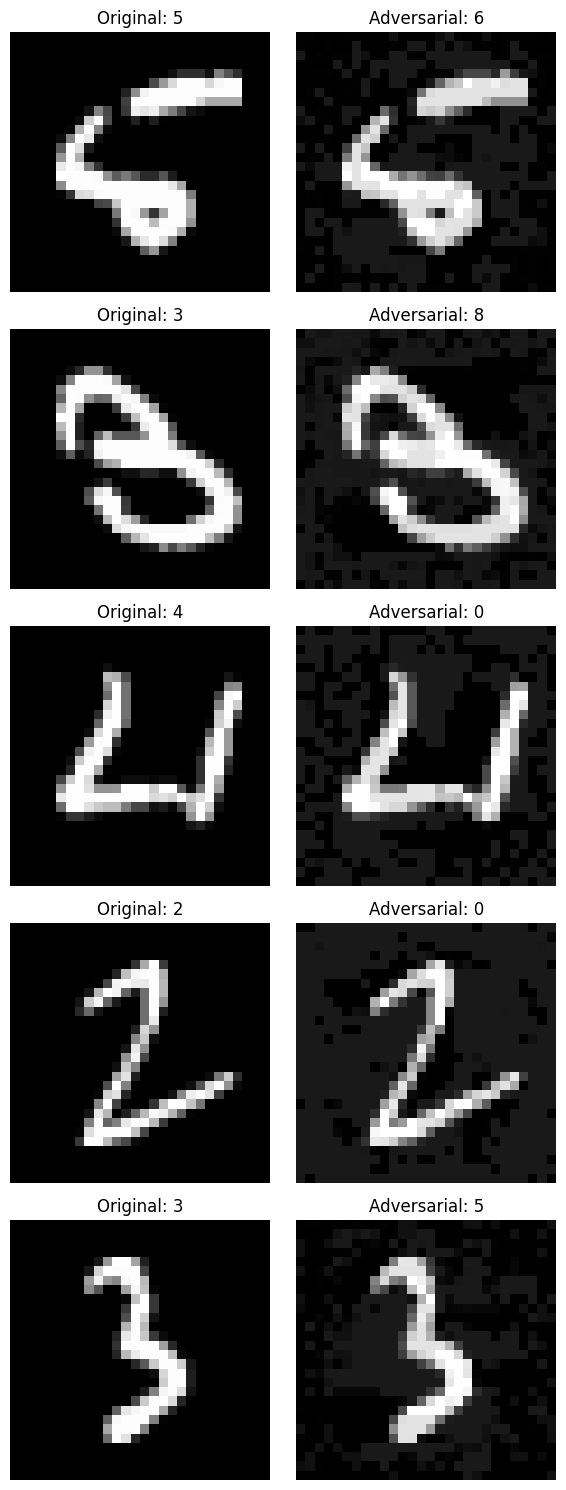

In [55]:
if successful_examples:
    n = min(5, len(successful_examples))

    fig, axes = plt.subplots(n, 2, figsize=(6, 3*n))

    if n == 1:
        axes = [axes]

    for row, example in enumerate(successful_examples[:n]):
        axes[row][0].imshow(example["clean"], cmap="gray")
        axes[row][0].set_title(
            f'Original: {example["true_label"]}'
        )

        axes[row][1].imshow(example["adversarial"], cmap="gray")
        axes[row][1].set_title(
            f'Adversarial: {example["adversarial_prediction"]}'
        )

        axes[row][0].axis("off")
        axes[row][1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No successful adversarial examples found in this run.")

In [56]:
for example in successful_examples:
    difference = (
        example["adversarial"] - example["clean"]
    ).abs().max().item()

    print(
        f'Image {example["index"]}: '
        f'{example["true_label"]} -> '
        f'{example["adversarial_prediction"]}, '
        f'L-inf distance = {difference:.5f}'
    )

Image 8: 5 -> 6, L-inf distance = 0.10000
Image 18: 3 -> 8, L-inf distance = 0.10000
Image 33: 4 -> 0, L-inf distance = 0.10000
Image 38: 2 -> 0, L-inf distance = 0.10000
Image 44: 3 -> 5, L-inf distance = 0.10000
Image 59: 5 -> 7, L-inf distance = 0.10000
Image 62: 9 -> 5, L-inf distance = 0.10000
Image 65: 4 -> 9, L-inf distance = 0.10000
Image 66: 6 -> 4, L-inf distance = 0.10000
Image 78: 9 -> 8, L-inf distance = 0.10000
Image 87: 3 -> 5, L-inf distance = 0.10000
Image 97: 7 -> 8, L-inf distance = 0.10000
